# Subjects and a defection model

Roadmap step 3, part 3. Which subjects see the most defection from the political group, and which characteristics of members and roll calls go with defecting?

- **Subject** is the responsible committee recorded for the roll call (17,660 of 25,688 roll calls; 1,196 with joint committees are grouped as such). Roll calls without a committee are a separate category.
- **Odds ratios** come from a logistic regression in each term, on a sample of 300,000 positions, with errors clustered by member and by roll call.
- **Prediction** follows the project's time split: train on the 9th term, test on the 10th, against a constant rate and the member's own earlier rate.

Defection and contested roll calls are defined as in notebook 01. Everything here is an association in requested roll calls, not a cause.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent))
sys.path.append(str(Path.cwd().parents[1] / "data_loading"))
from explanation import NON_ATTACHED, POSITIONS, defection_rows, follows, independent_party_ids
from howtheyvote import load, load_rollcalls, load_votes

SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # categorical slots 1 to 3
NEUTRAL = "#52514e"
MUTED = "#c9c8c1"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})

TERMS = [9, 10]
# Display order from the polarization clustering maps; non-attached members last.
GROUP_ORDER = ["GREEN_EFA", "GUE_NGL", "SD", "RENEW", "EPP", "ECR", "ID", "PFE", "ESN", "NI"]
LABELS = {"GUE_NGL": "The Left", "GREEN_EFA": "Greens/EFA", "SD": "S&D", "RENEW": "Renew", "EPP": "EPP",
          "ECR": "ECR", "ID": "ID", "PFE": "PfE", "ESN": "ESN", "NI": "Non-attached"}
TERM_10_START = pd.Timestamp("2024-07-16")


def half_label(value):
    return f"{int(value)} {'H2' if value % 1 else 'H1'}"


def ordered(index):
    return [g for g in GROUP_ORDER if g in set(index)]


rollcalls = load_rollcalls()
rollcalls = rollcalls[~rollcalls["is_secret"]].set_index("vote_id")
rollcalls["half"] = rollcalls["date"].dt.year + (rollcalls["date"].dt.month > 6) * 0.5
# Responsible committee as the topic of a roll call. 1,196 roll calls have two or three (joint committees).
committees = load("subjects").query("scheme == 'committee'")
joint = committees.groupby("vote_id")["code"].nunique() > 1
first = committees.drop_duplicates("vote_id").set_index("vote_id")
rollcalls["committee"] = first["code"].where(~joint.reindex(first.index), "JOINT")
COMMITTEE_LABELS = dict(zip(committees["code"], committees["label"])) | {"JOINT": "Joint committees"}

# Members filed under the export's "Independent" entries have no national party.
independents = independent_party_ids(load("national_parties"))
frames = []
for term in TERMS:
    frames.append(defection_rows(load_votes(term), no_party_ids=independents))
rows = pd.concat(frames, ignore_index=True)
del frames
rows = rows.join(rollcalls[["half", "minority_share", "minority_share_with_abstention", "vote_part",
                            "committee"]], on="vote_id")
contested = rows[rows["minority_share"] >= 0.025]
print(f"{len(rows):,} active positions; {len(contested):,} on contested roll calls")

import statsmodels.formula.api as smf
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from explanation import lagged_rate, shift_share, two_way

SEED = 0
data = contested[(contested["group_code"] != NON_ATTACHED) & contested["defected_group"].notna()].copy()
data["committee"] = data["committee"].fillna("NONE")

# Member characteristics.
members = load("members").set_index("member_id")
data["age"] = data["half"].astype(float) - members["date_of_birth"].dt.year.reindex(data["member_id"]).to_numpy()
party_size = rows.groupby(["term", "national_party_id"])["member_id"].nunique().rename("party_members")
data = data.join(party_size, on=["term", "national_party_id"])
data["no_party"] = data["national_party_id"].isna() | data["national_party_id"].isin(independents)
data["party_size"] = pd.cut(data["party_members"].where(~data["no_party"], 1), [0, 1, 3, 9, 200],
                            labels=["none or 1", "2 to 3", "4 to 9", "10 or more"])

# Earlier behaviour: the member's and the group's defection rate in the last earlier half-year.
member_lag = lagged_rate(data, "half")
data = data.merge(member_lag, on=["member_id", "half"], how="left")
group_rates = data.groupby(["group_code", "half"])["defected_group"].mean().rename("group_rate").reset_index()
group_rates["group_lagged_rate"] = group_rates.sort_values("half").groupby("group_code")["group_rate"].shift(1)
data = data.merge(group_rates[["group_code", "half", "group_lagged_rate"]], on=["group_code", "half"], how="left")
data["colleagues"] = np.select(
    [data["party_line"] < 0, data["party_line"] == data["group_line"]],
    ["no united colleagues", "colleagues with the group"], "colleagues against the group")
print(f"{len(data):,} positions with a group line; defection rate {data['defected_group'].mean():.3f}")
print("Missing birth year:", round(data["age"].isna().mean(), 3))

16,616,129 active positions; 15,624,395 on contested roll calls


14,858,390 positions with a group line; defection rate 0.087
Missing birth year: 0.109


## Defection by subject

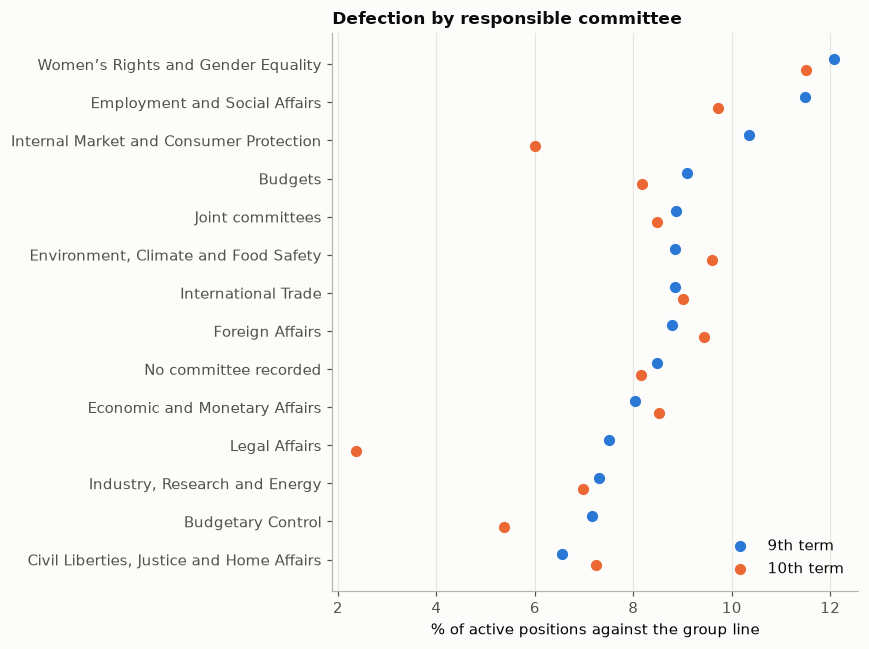

rollcalls         defection         \
term                                             9       10        9      10   
Civil Liberties, Justice and Home Affairs     661.0   338.0     0.066  0.072   
Budgetary Control                            1137.0   325.0     0.072  0.054   
Industry, Research and Energy                 338.0   163.0     0.073  0.070   
Legal Affairs                                 278.0   175.0     0.075  0.024   
Economic and Monetary Affairs                 658.0   219.0     0.080  0.085   
No committee recorded                        5934.0  1471.0     0.085  0.082   
Foreign Affairs                              1691.0   685.0     0.088  0.094   
International Trade                           112.0   179.0     0.088  0.090   
Environment, Climate and Food Safety         1889.0   363.0     0.088  0.096   
Joint committees                              691.0   460.0     0.089  0.085   
Budgets                                       430.0   472.0     0.091  0.082   
Internal Market and Consumer Protection       305.0   117.0     0.104  0.060   
Employment and Social Affairs                 688.0   221.0     0.115  0.097   
Women’s Rights and Gender Equality            294.0   246.0     0.121  0.115   

                                          colleagues_against         
term                                                      9      10  
Civil Liberties, Justice and Home Affairs              0.033  0.030  
Budgetary Control                                      0.039  0.024  
Industry, Research and Energy                          0.033  0.035  
Legal Affairs                                          0.037  0.008  
Economic and Monetary Affairs                          0.047  0.043  
No committee recorded                                  0.041  0.037  
Foreign Affairs                                        0.048  0.044  
International Trade                                    0.042  0.042  
Environment, Climate and Food Safety                   0.042  0.046  
Joint committees                                       0.041  0.041  
Budgets                                                0.047  0.041  
Internal Market and Consumer Protection                0.054  0.031  
Employment and Social Affairs                          0.065  0.046  
Women’s Rights and Gender Equality                     0.052  0.039

Spearman correlation of committee defection rates between terms: 0.622


In [2]:
by_committee = data.groupby(["committee", "term"]).agg(
    rollcalls=("vote_id", "nunique"), defection=("defected_group", "mean"),
    colleagues_against=("colleagues", lambda s: s.eq("colleagues against the group").mean())).unstack("term")
shown = by_committee[(by_committee["rollcalls"] >= 100).all(axis=1)].sort_values(("defection", 9))
fig, axis = plt.subplots(figsize=(8, 6))
positions = np.arange(len(shown))
for term, color, offset in zip(TERMS, SERIES, [0.15, -0.15]):
    axis.scatter(shown[("defection", term)] * 100, positions + offset, s=40, color=color, label=f"{term}th term", zorder=3)
axis.set_yticks(positions, [COMMITTEE_LABELS.get(code, "No committee recorded") for code in shown.index])
axis.set_xlabel("% of active positions against the group line")
axis.set_title("Defection by responsible committee")
axis.legend(loc="lower right")
axis.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()
table = shown.copy()
table.index = [COMMITTEE_LABELS.get(code, "No committee recorded") for code in table.index]
display(table.round(3))
print("Spearman correlation of committee defection rates between terms:",
      round(shown[("defection", 9)].corr(shown[("defection", 10)], method="spearman"), 3))

**What this shows**

- **Women's Rights and Gender Equality has the most defection in both terms** (12.1% and 11.5%), followed in the 9th term by Employment and Social Affairs (11.5%) and Internal Market (10.4%).
- **Civil Liberties, Budgetary Control, Industry and Legal Affairs have the least** (6.6% to 7.5% in the 9th term). Legal Affairs fell to 2.4% in the 10th.
- **Most subjects lie between 7% and 10%,** and their order is fairly stable (Spearman 0.62 between terms).
- Subjects matter much less than groups: the gap between subjects is a few points, against 2% to 23% between groups.

Committees are a coarse proxy for subject. Votes on the same subject can be very different in importance.

In [3]:
periods = {}
for term in TERMS:
    part = data[data["term"] == term]
    periods[term] = pd.DataFrame({"rate": part.groupby("committee")["defected_group"].mean(),
                                  "weight": part["committee"].value_counts(normalize=True)})
parts = shift_share(periods[9], periods[10])
print("Change in the defection rate from the 9th to the 10th term, split by responsible committee:")
display(pd.Series(parts).round(4).to_frame("change"))

Change in the defection rate from the 9th to the 10th term, split by responsible committee:


,change
total,-0.0058
within_topics,-0.0035
topic_mix,-0.0023


**The fall in defection between terms is spread across subjects.** The rate fell by 0.58 points. About 0.35 points came from lower defection within subjects and 0.23 from a different mix of subjects. The mix also includes roll calls without a recorded committee.

## Who defects: odds ratios in each term

References: EPP members, amendments, roll calls from the Environment committee, members of national parties with 10 or more members in the term. Age is per 10 years. The first model uses only characteristics of the member and the roll call. The second adds what the member's national party colleagues did on the same roll call, which describes the vote rather than predicting it.

In [4]:
TOP_COMMITTEES = data["committee"].value_counts().index[:12]
data["committee_top"] = data["committee"].where(data["committee"].isin(TOP_COMMITTEES), "OTHER")
BASE = ("defected_group ~ C(group_code, Treatment('EPP')) + C(vote_part, Treatment('amendment'))"
        " + C(committee_top, Treatment('ENVI')) + age_10 + C(party_size, Treatment('10 or more'))")
WITH_COLLEAGUES = BASE + " + C(colleagues, Treatment('colleagues with the group'))"


def odds(fit):
    ci = fit.conf_int()
    table = pd.DataFrame({"odds_ratio": np.exp(fit.params), "low": np.exp(ci[0]), "high": np.exp(ci[1])}).drop(index="Intercept")
    table.index = (table.index.str.replace(r"C\((\w+), Treatment\('[^']*'\)\)\[T\.", r"\1: ", regex=True).str.rstrip("]"))
    return table


fits, samples = {}, {}
for term in TERMS:
    sample = data[(data["term"] == term) & data["age"].notna()].sample(300000, random_state=SEED).copy()
    sample["age_10"] = sample["age"] / 10
    sample["party_size"] = sample["party_size"].astype(str)
    samples[term] = sample
    for name, formula in [("member and roll call", BASE), ("with colleagues", WITH_COLLEAGUES)]:
        fits[(term, name)] = smf.logit(formula, data=sample).fit(disp=False, cov_type="cluster", cov_kwds=two_way(sample))
table = pd.concat({f"{term}th, {name}": odds(fit)["odds_ratio"] for (term, name), fit in fits.items()}, axis=1)
intervals = pd.concat({f"{term}th": odds(fits[(term, "member and roll call")]).apply(
    lambda r: f"{r['low']:.2f}-{r['high']:.2f}", axis=1) for term in TERMS}, axis=1).add_suffix(" 95% interval")
display(table.round(2).join(intervals))

,"9th, member and roll call","9th, with colleagues","10th, member and roll call","10th, with colleagues",9th 95% interval,10th 95% interval
group_code: ECR,2.34,1.26,2.10,1.59,1.85-2.96,1.75-2.53
group_code: GREEN_EFA,0.28,0.33,0.44,0.51,0.23-0.35,0.34-0.57
group_code: GUE_NGL,1.11,0.92,0.90,0.86,0.90-1.36,0.72-1.12
group_code: ID,5.23,2.43,NaN,NaN,4.62-5.91,NaN
group_code: RENEW,0.83,0.63,0.53,0.46,0.70-0.97,0.43-0.65
group_code: SD,0.71,0.71,0.69,0.73,0.61-0.81,0.57-0.84
vote_part: final,1.18,1.04,1.36,1.22,1.09-1.28,1.25-1.49
vote_part: other,0.82,0.70,1.17,1.11,0.72-0.94,0.96-1.43
vote_part: procedural,1.14,1.03,0.94,0.99,0.94-1.38,0.75-1.18
vote_part: text part,1.10,1.01,1.28,1.14,1.04-1.17,1.20-1.37


**What this shows**

- **Group is the strongest member-level association:**
  - ID members had 5.2 times the odds of an EPP member of defecting in the 9th term.
  - ECR members 2.3 and 2.1 times; PfE 2.5 and ESN 1.7 times in the 10th.
  - Greens/EFA members had a quarter to under half the EPP's odds; S&D members about 0.7 times.
- **Members of national parties with fewer than 10 members defect at about twice the odds of those in larger national parties** (1.9 to 2.3), and so do members without a national party.
- **Final votes and text parts carry somewhat higher odds than amendments** (1.1 to 1.4). Budgetary Control and Civil Liberties roll calls carry lower odds (0.5 to 0.8).
- **Age shows no clear association** (0.97 per 10 years, intervals including 1).
- **Adding the national colleagues' votes on the same roll call changes the picture:**
  - Voting where colleagues were united against the group line multiplies the odds by about 4,400. This is close to a restatement of the vote, not an explanation.
  - With it included, members of small national parties no longer defect more (0.4 to 0.5 for parties of 2 to 3). Their extra defection was collective.
  - The gap between groups shrinks: ID 2.4, ECR 1.3 and 1.6, PfE 1.3.

These are associations in the requested roll calls of each term, with errors clustered by member and roll call.

## Predicting defection in the 10th term

Train on the 9th term (from 2020, so every member can have an earlier half-year), test on the 10th. Features known before the roll call:

- the member's defection rate in their last earlier half-year, and the group's;
- kind of roll call, responsible committee, the member's country, age and national party size.

Group identity isn't used, because groups changed between terms. Fill values for missing features come from the training data only. The last model adds the national party colleagues' votes on the same roll call; that is only known after the vote, so it describes the vote rather than forecasting it.

In [5]:
model_data = data.copy()
train_rows = model_data[(model_data["term"] == 9) & (model_data["half"] >= 2020.0)]
fill = {"lagged_rate": train_rows["lagged_rate"].mean(), "group_lagged_rate": train_rows["group_lagged_rate"].mean(),
        "age": train_rows["age"].median()}
for column, value in fill.items():
    model_data[f"has_{column}"] = model_data[column].notna().astype(int)
    model_data[column] = model_data[column].fillna(value)
model_data["party_size"] = model_data["party_size"].astype(str)
train = model_data[(model_data["term"] == 9) & (model_data["half"] >= 2020.0)].sample(1_500_000, random_state=SEED)
test = model_data[model_data["term"] == 10]
print(f"Train: {len(train):,} positions (sample), rate {train['defected_group'].mean():.3f}. "
      f"Test: {len(test):,} positions, rate {test['defected_group'].mean():.3f}")

NUMERIC = ["lagged_rate", "group_lagged_rate", "age"]
FLAGS = ["has_lagged_rate", "has_group_lagged_rate", "has_age"]
CATEGORIES = ["vote_part", "committee", "country_code", "party_size"]


def logistic(numeric, flags, categories):
    return make_pipeline(ColumnTransformer([("num", StandardScaler(), numeric), ("flag", "passthrough", flags),
                                            ("cat", OneHotEncoder(handle_unknown="ignore"), categories)]),
                         LogisticRegression(max_iter=3000))


def evaluate(name, probability):
    truth = test["defected_group"].to_numpy()
    return {"model": name, "auc": roc_auc_score(truth, probability), "average_precision": average_precision_score(truth, probability),
            "log_loss": log_loss(truth, np.clip(probability, 1e-6, 1 - 1e-6)), "brier": brier_score_loss(truth, probability),
            "mean_prediction": float(np.mean(probability))}


target = train["defected_group"].astype(int)
results = [evaluate("constant training rate", np.full(len(test), target.mean()))]
member_history = logistic(["lagged_rate"], ["has_lagged_rate"], []).fit(train, target)
results.append(evaluate("member's earlier rate", member_history.predict_proba(test)[:, 1]))
full = logistic(NUMERIC, FLAGS, CATEGORIES).fit(train, target)
results.append(evaluate("logistic regression", full.predict_proba(test)[:, 1]))
boosting = make_pipeline(
    ColumnTransformer([("num", "passthrough", NUMERIC + FLAGS),
                       ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False, min_frequency=1000), CATEGORIES)]),
    HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=SEED)).fit(train, target)
results.append(evaluate("gradient boosting", boosting.predict_proba(test)[:, 1]))
with_colleagues = logistic(NUMERIC, FLAGS, CATEGORIES + ["colleagues"]).fit(train, target)
results.append(evaluate("logistic + colleagues' votes (same roll call)", with_colleagues.predict_proba(test)[:, 1]))
display(pd.DataFrame(results).set_index("model").round(4))
print("Average precision with no information equals the test defection rate:", round(test["defected_group"].mean(), 4))

Train: 1,500,000 positions (sample), rate 0.088. Test: 3,742,592 positions, rate 0.082


,auc,average_precision,log_loss,brier,mean_prediction
model,,,,,
constant training rate,0.5000,0.0825,0.2850,0.0757,0.0885
member's earlier rate,0.7019,0.1757,0.2670,0.0727,0.0864
logistic regression,0.6936,0.1749,0.2663,0.0725,0.0866
gradient boosting,0.7094,0.1804,0.2638,0.0723,0.0892
logistic + colleagues' votes (same roll call),0.9196,0.6985,0.1473,0.0396,0.0823


Average precision with no information equals the test defection rate: 0.0825


In [6]:
rng = np.random.default_rng(SEED)
draws = []
truth = test["defected_group"].to_numpy()
probabilities = {"member's earlier rate": member_history.predict_proba(test)[:, 1],
                 "logistic regression": full.predict_proba(test)[:, 1],
                 "gradient boosting": boosting.predict_proba(test)[:, 1]}
rollcall_codes, rollcall_index = np.unique(test["vote_id"].to_numpy(), return_inverse=True)
for draw in range(50):
    chosen = rng.integers(0, len(rollcall_codes), len(rollcall_codes))
    weights = np.bincount(chosen, minlength=len(rollcall_codes))[rollcall_index]
    keep = weights > 0
    row = {name: roc_auc_score(truth[keep], p[keep], sample_weight=weights[keep]) for name, p in probabilities.items()}
    draws.append(row)
draws = pd.DataFrame(draws)
gains = pd.DataFrame({
    "logistic over earlier rate": draws["logistic regression"] - draws["member's earlier rate"],
    "boosting over logistic": draws["gradient boosting"] - draws["logistic regression"],
    "boosting over earlier rate": draws["gradient boosting"] - draws["member's earlier rate"],
})
print("AUC differences over 50 bootstrap draws of test roll calls (2.5th, 50th and 97.5th percentiles):")
display(gains.quantile([0.025, 0.5, 0.975]).round(4))

AUC differences over 50 bootstrap draws of test roll calls (2.5th, 50th and 97.5th percentiles):


,logistic over earlier rate,boosting over logistic,boosting over earlier rate
0.025,-0.0100,0.0144,0.0053
0.500,-0.0084,0.0159,0.0075
0.975,-0.0069,0.0179,0.0090


**What this shows**

- **The test defection rate is 8.25%,** so average precision of 0.0825 means no information.
- **The member's own rate in their previous half-year is a strong baseline:** AUC 0.702, average precision 0.176.
- **Adding roll-call and member characteristics in a logistic regression doesn't help on the 10th term:** AUC 0.694, slightly worse than the own-rate baseline (by 0.007 to 0.010 across bootstrap draws of roll calls).
- **Gradient boosting does a little better:** AUC 0.709 and average precision 0.180, above the own-rate baseline by 0.005 to 0.009 across draws.
- **What the member's national party colleagues did on the same roll call lifts AUC to 0.920 and average precision to 0.699.** That information comes from the vote itself. It shows that defection is mostly collective, not that it can be predicted in advance.

So, as in the USA, defection is hard to predict before the vote beyond each member's own record. The USA's best defection model reached AUC 0.707 against 0.697 for own history, though on a different definition and chamber.

## Summary

- Subjects matter less than groups. Women's Rights and Employment roll calls see the most defection, Budgetary Control and Civil Liberties the least, in both terms.
- Members of small national parties defect at about twice the odds of those in large ones. This is explained by national colleagues defecting with them.
- Final votes and votes on parts of a text carry slightly higher odds of defection than amendments. Age shows no association.
- Before the vote, a member's own earlier defection rate is the best single predictor (AUC 0.70). Gradient boosting with roll-call and member characteristics adds 0.007. The national colleagues' votes on the roll call itself raise AUC to 0.92, which describes collective defection rather than predicting it.